In [33]:
import pandas as pd
from sqlalchemy import create_engine
import numpy as np

In [34]:
path = "data/heat_exchanger.db"

engine = create_engine(f"sqlite:///{path}")


df = pd.read_sql("SELECT * FROM heat_exchanger",engine)

df['timestamp'] = pd.to_datetime(df["timestamp"])
df['day_index'] = (df['timestamp'] - df['timestamp'].min()).dt.days
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   timestamp                 175 non-null    datetime64[us]
 1   water_inlet_temperature   175 non-null    float64       
 2   glycol_inlet_temperature  175 non-null    float64       
 3   out_glycol_temperature    175 non-null    float64       
 4   out_water_temperature     175 non-null    float64       
 5   heat_efficiency           175 non-null    float64       
 6   day_index                 175 non-null    int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 9.7 KB


In [35]:
df.isnull().sum()

timestamp                   0
water_inlet_temperature     0
glycol_inlet_temperature    0
out_glycol_temperature      0
out_water_temperature       0
heat_efficiency             0
day_index                   0
dtype: int64

In [36]:
df.describe()

,timestamp,water_inlet_temperature,glycol_inlet_temperature,out_glycol_temperature,out_water_temperature,heat_efficiency,day_index
count,175,175.000000,175.000000,175.000000,175.000000,175.000000,175.000000
mean,2025-12-27 08:21:56.571428,31.441943,69.699429,41.350343,51.461277,94.741801,89.348571
min,2025-09-29 00:00:00,20.850000,21.110000,20.700000,21.262971,93.225263,0.000000
25%,2025-11-11 12:00:00,30.910000,31.545000,31.565000,33.128821,93.921594,43.500000
50%,2025-12-27 00:00:00,32.100000,84.130000,45.580000,59.250579,94.691906,89.000000
75%,2026-02-10 12:00:00,32.770000,85.845000,46.485000,60.107158,95.536221,134.500000
max,2026-03-28 00:00:00,35.930000,89.180000,48.970000,64.060976,96.454517,180.000000
std,NaN,2.382263,24.781046,7.686540,13.872204,0.941302,52.465738


Text(0.5, 1.0, 'Heat Efficiency vs Day Index')

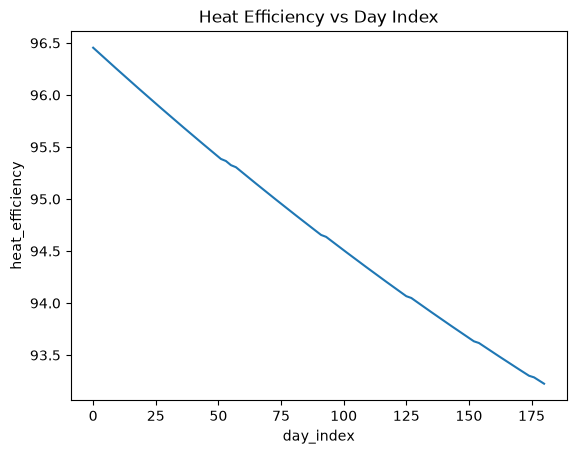

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.lineplot(df, x="day_index", y="heat_efficiency")
plt.title("Heat Efficiency vs Day Index")

In [39]:
x = df['day_index'].values
y = df['heat_efficiency'].values

coef = np.polyfit(x, y, 1)
print(f"Linear Regression Coefficients: {coef}")

Linear Regression Coefficients: [-1.79188688e-02  9.63428267e+01]


In [40]:
pred = np.polyval(coef, x)
pred

array([96.34282667, 96.3249078 , 96.30698893, 96.28907006, 96.27115119,
       96.25323232, 96.23531345, 96.21739459, 96.19947572, 96.18155685,
       96.16363798, 96.14571911, 96.12780024, 96.10988137, 96.0919625 ,
       96.07404363, 96.05612477, 96.0382059 , 96.02028703, 96.00236816,
       95.98444929, 95.96653042, 95.94861155, 95.93069268, 95.91277382,
       95.89485495, 95.87693608, 95.85901721, 95.84109834, 95.82317947,
       95.8052606 , 95.78734173, 95.76942286, 95.751504  , 95.73358513,
       95.71566626, 95.69774739, 95.67982852, 95.66190965, 95.64399078,
       95.62607191, 95.60815305, 95.59023418, 95.57231531, 95.55439644,
       95.53647757, 95.5185587 , 95.50063983, 95.48272096, 95.46480209,
       95.44688323, 95.42896436, 95.39312662, 95.37520775, 95.35728888,
       95.32145114, 95.30353228, 95.28561341, 95.26769454, 95.24977567,
       95.2318568 , 95.21393793, 95.19601906, 95.17810019, 95.16018133,
       95.14226246, 95.12434359, 95.10642472, 95.08850585, 95.07

Text(0.5, 1.0, 'Actual vs Predicted Heat Efficiency')

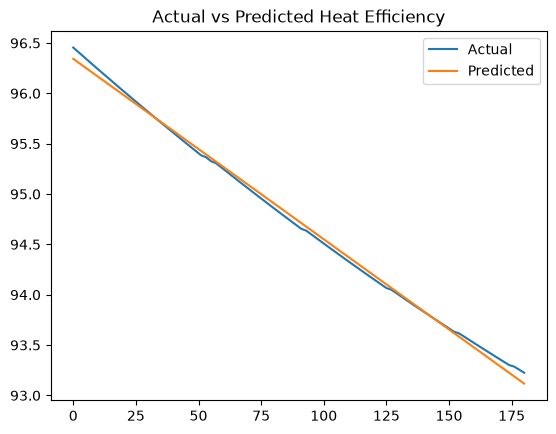

In [41]:
sns.lineplot(x=x, y=y, label='Actual')
sns.lineplot(x=x, y=pred, label='Predicted')
plt.title("Actual vs Predicted Heat Efficiency")



In [42]:
from sklearn.metrics import r2_score

r2 = r2_score(y, pred)
print(f"R-squared: {r2}")

R-squared: 0.9975040682379518
